# EEG Processing - starting with epochs

This notebook processes EEG data from the INTRA dataset. The recordings capture interictal spikes extracted from resting-state EEG of patients with epilepsy, with each segment spanning 4 seconds centered on the spike peak. Therefore, the data is already epoched.

## 🧪 - Experiment setup
- `eeg`: 'raw' EEG.

In [1]:
%matplotlib widget
import mindmap as mm
import mne

# reader
dm = mm.io.TutoManager("../../config.yml")
sr = dm.get_subject("intra-12")

# data
eeg = sr.load("eeg", task="spk")

## 🧬 - Data Processing
1. **Bad channel detection/interpolation**: Inspect the Fourier spectrum for outliers and examine the topography at the spike peak to identify any abrupt spatial changes indicative of faulty channels. Interpolate bad channels.

Inspect Fourier spectrum

    Using multitaper spectrum estimation with 7 DPSS windows
Plotting power spectral density (dB=True).
Averaging across epochs before plotting...


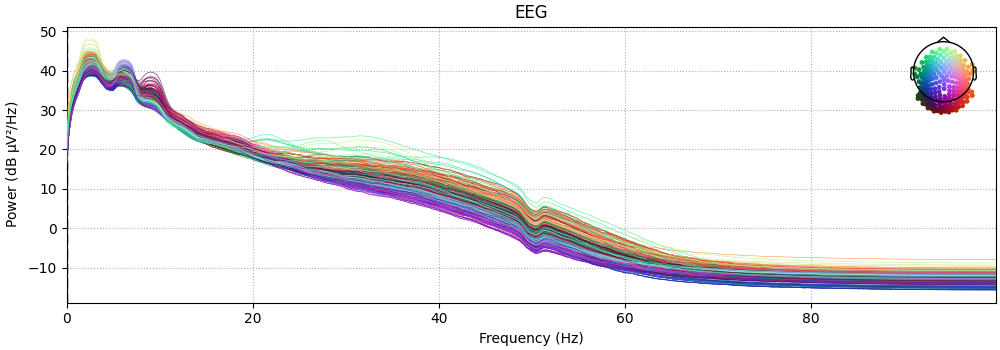

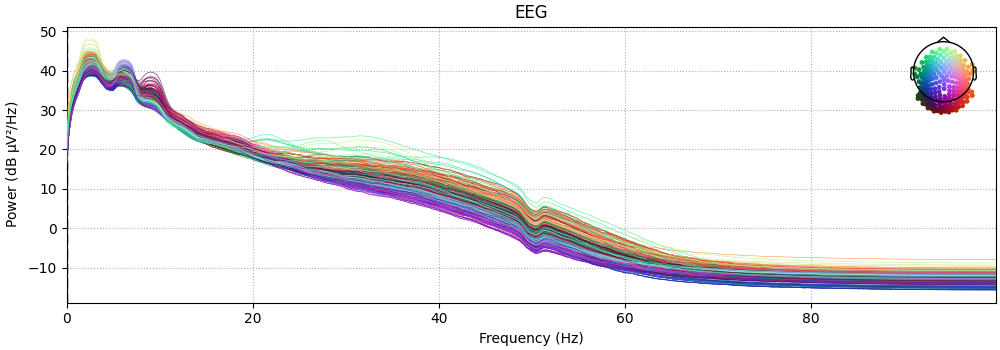

In [2]:
psd = eeg.compute_psd().plot()

Interpolate bad channels

In [3]:
bads = []

for b in bads:
    eeg.info["bads"].append(b)
eeg = eeg.interpolate_bads(method={"eeg":"spline"})

Setting channel interpolation method to {'eeg': 'spline'}.


/tmp/ipykernel_17620/3788888521.py:5: RuntimeWarning: No bad channels to interpolate. Doing nothing...
  eeg = eeg.interpolate_bads(method={"eeg":"spline"})


2. **Add average referencing**

In [4]:
eeg = eeg.set_eeg_reference(ref_channels="average", projection=True)

EEG channel type selected for re-referencing
Adding average EEG reference projection.
1 projection items deactivated
Average reference projection was added, but has not been applied yet. Use the apply_proj method to apply it.


3. **Apply baseline correction**

In [5]:
eeg = eeg.apply_baseline(baseline=[0,1.5])

Applying baseline correction (mode: mean)


4. **Compute noise covariance matrix**

In [6]:
noise_cov = mne.compute_covariance(eeg, tmax=1.5, method="empirical")       # uses projectors (avg ref) of epochs

    Created an SSP operator (subspace dimension = 1)
    Setting small EEG eigenvalues to zero (without PCA)
Reducing data rank from 208 -> 207
Estimating covariance using EMPIRICAL
Done.
Number of samples used : 77357
[done]


5. **Average epochs**

In [7]:
evoked = eeg.average()

## 📊 - Visualization

There are many aspects of EEG data to visualize. Let’s generate an MNE report so that all plots can be explored in a web browser.

In [8]:
mm.viz.create_pipeline_report(evoked, noise_cov, subject_id = sr.sub)

Embedding : jquery-3.6.0.min.js
Embedding : bootstrap.bundle.min.js
Embedding : bootstrap.min.css
Embedding : bootstrap-table/bootstrap-table.min.js
Embedding : bootstrap-table/bootstrap-table.min.css
Embedding : bootstrap-table/bootstrap-table-copy-rows.min.js
Embedding : bootstrap-table/bootstrap-table-export.min.js
Embedding : bootstrap-table/tableExport.min.js
Embedding : bootstrap-icons/bootstrap-icons.mne.min.css
Embedding : highlightjs/highlight.min.js
Embedding : highlightjs/atom-one-dark-reasonable.min.css
Created an SSP operator (subspace dimension = 1)
1 projection items activated
SSP projectors applied...


[Parallel(n_jobs=1)]: Done  17 tasks      | elapsed:    1.8s
[Parallel(n_jobs=1)]: Done  21 out of  21 | elapsed:    2.3s finished


NOTE: pick_types() is a legacy function. New code should use inst.pick(...).
Computing rank from covariance with rank=None
    Using tolerance 9.9e-12 (2.2e-16 eps * 208 dim * 2.1e+02  max singular value)
    Estimated rank (eeg): 207
    EEG: rank 207 computed from 208 data channels with 1 projector
    Created an SSP operator (subspace dimension = 1)
Computing rank from covariance with rank={'eeg': 207}
    Setting small EEG eigenvalues to zero (without PCA)
    Created the whitener using a noise covariance matrix with rank 207 (1 small eigenvalues omitted)
Created an SSP operator (subspace dimension = 1)
1 projection items activated
SSP projectors applied...
Overwriting existing file.
Saving report to : /home/nino/Code/mindmap/tutorials/analysis/eeg/Report_intra-12.html
Report saved for intra-12
